# Forecasting Ho Chi Minh City Hourly Humidity — 5 Hours Ahead
**Encoder–Decoder (seq2seq) GRU + Attention** · repo `hcm-humidity-forecast`

**Task.** Forecast `humidity` (the `pred_column`) for the **next 5 consecutive hours**, and evaluate with **R², NSE, MAE, RMSE**.
**Data.** `weather_hcm_hourly.csv` — hourly weather observations for Ho Chi Minh City.

### Pipeline
| # | Step | Where |
|---|------|-------|
| 1 | Data understanding | section 1 |
| 2 | Cleaning, features, chronological split, sliding windows (no leakage) | `src/data.py` |
| 3 | Evaluation metrics (R², NSE, MAE, RMSE) per step and pooled | `src/metrics.py` |
| 4 | Reference models: persistence, climatology, Ridge (linear regression) | `src/baselines.py` |
| 5 | Encoder–Decoder GRU, with and without Attention | `src/model.py` |
| 6 | Training (teacher forcing, early stopping) | `src/train.py` |
| 7 | Results on the test set | section 5 |
| 8 | Analysis of the final model: forecasts, errors, attention | section 6 |

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import data as D, metrics as M, baselines as B
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
cfg = D.load_config(); ROOT = D.ROOT; FIG = ROOT / "reports" / "figures"
F = "hourly"
RETRAIN = False        # True = retrain every model (~15 min on 1 CPU); False = load saved results/weights
print(json.dumps({k: cfg[k] for k in ("target", "horizon", "split")}), "| look-back:", cfg["datasets"][F]["lookback"], "hours")

{"target": "humidity", "horizon": 5, "split": {"train": 0.7, "val": 0.15, "test": 0.15}} | look-back: 48 hours


## 1. Data understanding

In [2]:
raw = pd.read_csv(ROOT / cfg["datasets"][F]["path"], encoding="utf-8-sig", parse_dates=["datetime"])
step = raw.datetime.diff().mode()[0]
summary = pd.Series({"rows": len(raw), "columns": raw.shape[1], "start": raw.datetime.min(), "end": raw.datetime.max(),
                     "time step": str(step), "gaps in time index": int((raw.datetime.diff().dropna() != step).sum()),
                     "humidity missing": int(raw.humidity.isna().sum()), "humidity mean (%)": round(raw.humidity.mean(), 2),
                     "humidity std (%)": round(raw.humidity.std(), 2), "humidity min / max (%)": f"{raw.humidity.min():.1f} / {raw.humidity.max():.1f}"})
display(summary.to_frame("hourly file"))
miss = raw.isna().mean().mul(100).round(1); display(miss[miss > 0].to_frame("% missing").T)

,hourly file
rows,94248
columns,26
start,2015-01-01 00:00:00
end,2025-10-01 23:00:00
time step,0 days 01:00:00
gaps in time index,0
humidity missing,0
humidity mean (%),76.57
humidity std (%),16.06
humidity min / max (%),17.9 / 100.0


,preciptype,windgust,visibility,severerisk
% missing,89.0,0.1,0.3,94.9


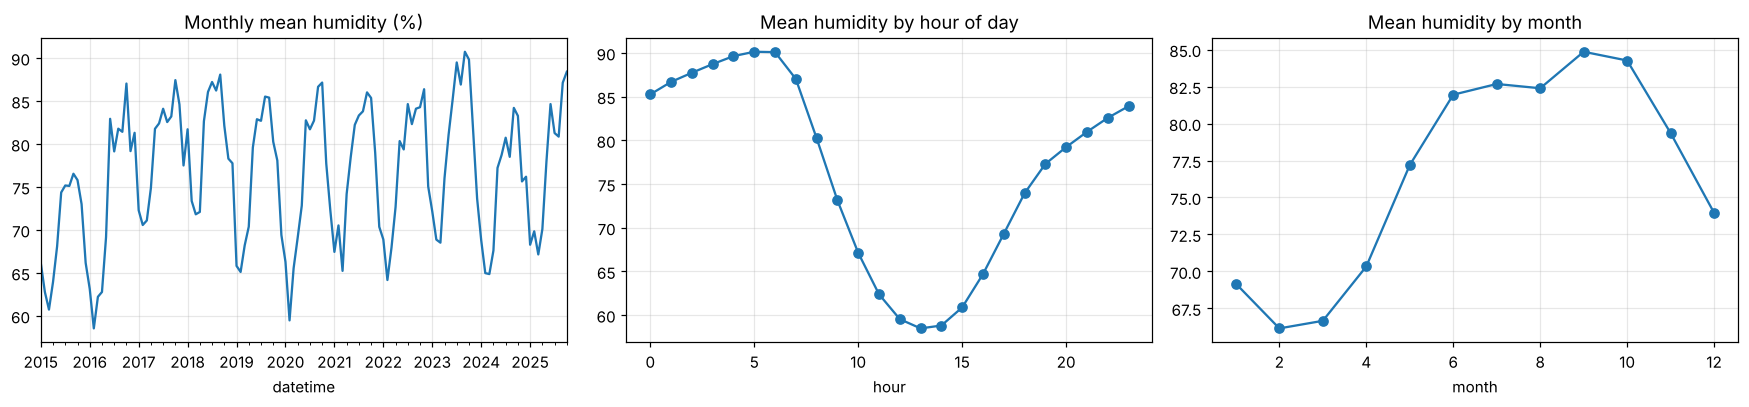

Diurnal cycle: peak 90% at 05:00, minimum 58% at 13:00
Seasonal cycle (monthly means): {1: 69.2, 2: 66.1, 3: 66.7, 4: 70.3, 5: 77.2, 6: 82.0, 7: 82.7, 8: 82.4, 9: 84.9, 10: 84.3, 11: 79.4, 12: 74.0}


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
raw.set_index("datetime").humidity.resample("MS").mean().plot(ax=ax[0]); ax[0].set_title("Monthly mean humidity (%)")
raw.groupby(raw.datetime.dt.hour).humidity.mean().plot(ax=ax[1], marker="o"); ax[1].set_title("Mean humidity by hour of day"); ax[1].set_xlabel("hour")
raw.groupby(raw.datetime.dt.month).humidity.mean().plot(ax=ax[2], marker="o"); ax[2].set_title("Mean humidity by month"); ax[2].set_xlabel("month")
plt.tight_layout(); plt.savefig(FIG / "01_eda.png"); plt.show()
hr = raw.groupby(raw.datetime.dt.hour).humidity.mean(); mo = raw.groupby(raw.datetime.dt.month).humidity.mean()
print(f"Diurnal cycle: peak {hr.max():.0f}% at {hr.idxmax():02d}:00, minimum {hr.min():.0f}% at {hr.idxmin():02d}:00")
print("Seasonal cycle (monthly means):", mo.round(1).to_dict())

**Reading the plots.** Humidity has two clocks. A **diurnal cycle**: very humid before dawn (about 90 % around 05:00–06:00) and driest in the early afternoon (about 58 % around 13:00). And a **seasonal cycle**: the rainy season, roughly June–October, is the most humid, with May a transition month. The series covers 2015-01-01 → 2025-10-01 hourly with **no gaps and no missing humidity values**. `severerisk` and `preciptype` are mostly empty and are not used. Because of these two cycles, hour-of-day and day-of-year are given to the model as cyclical features.

## 2. Preprocessing & windowing
* **Features (18):** 12 numeric (temp, feelslike, dew, humidity, precip, windgust, windspeed, sealevelpressure, cloudcover, visibility, solarradiation, uvindex), wind direction as sin/cos, day-of-year as sin/cos, hour-of-day as sin/cos. Small gaps are forward/back-filled; missing `precip` is set to 0.
* **Calendar features are known in advance**, so the decoder also receives them for the 5 future hours.
* **Chronological split 70 / 15 / 15** (train / validation / test), no shuffling. Scaler statistics come from the **training rows only**, so nothing from validation or test leaks in.
* **Sliding window.** Input = the last **48 hours** up to time *t*. Output = humidity at *t+1 … t+5*. *Assumption:* "starting from the current time step" is read as the forecast starting right after the last observed hour; changing it is a one-line shift in `make_windows`.

In [4]:
df, feats, cov = D.load_frame(cfg, F)
W = D.make_windows(df, feats, cov, cfg, F)
dts = lambda s: pd.to_datetime(W[s]["dates"])
pd.DataFrame({
    "samples": {s: len(W[s]["X"]) for s in ("train", "val", "test")},
    "period (last forecast hour)": {s: f"{dts(s).min().date()} → {dts(s).max().date()}" for s in ("train", "val", "test")},
}).T.astype(str)

,train,val,test
samples,65921,14133,14134
period (last forecast hour),2015-01-03 → 2022-07-11,2022-07-12 → 2024-02-20,2024-02-21 → 2025-10-01


In [5]:
print("Encoder input per sample :", W["train"]["X"].shape[1:], "(hours x features)")
print("Decoder known inputs     :", W["train"]["DC"].shape[1:], "(5 future hours x calendar features)")
print("Target per sample        :", W["train"]["Y"].shape[1:], "(5 future hours)")
print("Features:", feats)

Encoder input per sample : (48, 18) (hours x features)
Decoder known inputs     : (5, 4) (5 future hours x calendar features)
Target per sample        : (5,) (5 future hours)
Features: ['temp', 'feelslike', 'dew', 'humidity', 'precip', 'windgust', 'windspeed', 'sealevelpressure', 'cloudcover', 'visibility', 'solarradiation', 'uvindex', 'wd_sin', 'wd_cos', 'doy_sin', 'doy_cos', 'hr_sin', 'hr_cos']


## 3. Evaluation metrics for sequence-to-sequence forecasting
For $N$ test windows and horizon $H=5$: $y_{n,h}$ is the observed and $\hat y_{n,h}$ the predicted humidity at step $h$ of window $n$. Every metric is computed **per step $h$** (to see how skill decays with the horizon) and **pooled** over all $N\times H$ values (one headline number). Metrics are computed in humidity % after inverting the scaling and clipping to [0, 100].

| Metric | Formula | Meaning |
|---|---|---|
| **MAE** | $\frac1{n}\sum \lvert y-\hat y\rvert$ | average error in % points; robust to outliers |
| **RMSE** | $\sqrt{\frac1{n}\sum (y-\hat y)^2}$ | same unit, punishes large misses more |
| **NSE** (Nash–Sutcliffe) | $1-\frac{\sum (y-\hat y)^2}{\sum (y-\bar y)^2}$ | 1 = perfect, 0 = no better than predicting the observed mean, <0 = worse than the mean |
| **R²** | $\big(\mathrm{corr}(y,\hat y)\big)^2$ | share of variance the predictions *co-vary* with; blind to bias and scale errors |

NSE equals scikit-learn's `r2_score`. R² (squared correlation) is always ≥ NSE; a large gap means the model follows the shape but is biased.

In [6]:
from sklearn.metrics import r2_score
rng = np.random.default_rng(0); y = rng.normal(70, 10, (200, 5)); p = y + rng.normal(0, 4, y.shape) + 2
r = M.evaluate(y, p)["overall"]
print({k: round(v, 4) for k, v in r.items()}, "| sklearn r2_score:", round(r2_score(y.ravel(), p.ravel()), 4))
print("NSE == sklearn r2:", abs(r["NSE"] - r2_score(y.ravel(), p.ravel())) < 1e-9, "| R2 >= NSE (a +2 bias lowers NSE only):", r["R2"] >= r["NSE"])

{'R2': 0.8573, 'NSE': 0.784, 'MAE': 3.6822, 'RMSE': 4.5396} | sklearn r2_score: 0.784
NSE == sklearn r2: True | R2 >= NSE (a +2 bias lowers NSE only): True


## 4. Model
**Encoder–Decoder** (Chapter 8): the encoder GRU reads the past 48 hours and produces hidden states $h_1..h_{48}$; the decoder GRU generates the 5 outputs one by one, $s_k=g(y_{k-1}, x^{cal}_k, c_k, s_{k-1})$ then $\hat y_k = \mathrm{MLP}(s_k, c_k)$.

* **Without attention:** the context $c$ is the encoder's last hidden state (the fixed-length context vector of the lecture).
* **With additive (Bahdanau) attention:** at each decoder step $e_{k,i}=v^\top\tanh(W_1h_i+W_2s_{k-1})$, $\alpha_{k,i}=\mathrm{softmax}_i(e_{k,i})$, $c_k=\sum_i\alpha_{k,i}h_i$, so the decoder can choose which past hours matter for each forecast hour. Attention is included as the task requires and is tested against the no-attention variant (an ablation) rather than assumed to help.
* **Training** (Chapters 3–4): MSE loss, Adam mini-batch gradient descent, Glorot (Xavier) initialisation (Keras default), dropout 0.2, gradient-norm clipping, early stopping on the *free-running* validation loss. **Teacher forcing** is used on 50 % of the batches (decoder fed the true previous value); the other 50 % feed back the model's own prediction, as happens at test time. At evaluation the decoding is always free-running.

In [7]:
from src.model import Seq2Seq
for att in (False, True):
    m = Seq2Seq(cfg["model"]["units"], cfg["horizon"], att); t = W["test"]; m((t["X"][:2], t["DC"][:2], t["YL"][:2]))
    print(f"{'with' if att else 'without'} attention -> trainable parameters: {m.count_params():,}")
print("Hyper-parameters:", cfg["model"])

I0000 00:00:1795669794.964123     129 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795669795.007835     129 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1795669796.388118     129 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


without attention -> trainable parameters: 50,369


with attention -> trainable parameters: 58,625
Hyper-parameters: {'units': 64, 'dropout': 0.2, 'learning_rate': 0.001, 'batch_size': 128, 'max_epochs': 25, 'patience': 4, 'teacher_forcing_prob': 0.5, 'clipnorm': 1.0}


In [8]:
if RETRAIN:
    from src import train
    train.run(F)
z = np.load(ROOT / "reports" / f"{F}_test_predictions.npz", allow_pickle=True)
P = {k: z[k] for k in z.files if k not in ("y_true", "dates")}
P["Climatology"] = B.climatology(df, F, cfg, W)
Y, dates = z["y_true"], pd.to_datetime(z["dates"])
R = {k: M.evaluate(Y, v) for k, v in P.items()}
best = "Seq2Seq + Attention"
print("test windows:", len(Y), "| models:", list(P))

test windows: 14134 | models: ['Persistence', 'Ridge (linear)', 'Seq2Seq (no attention)', 'Seq2Seq + Attention', 'Climatology']


## 5. Results on the test set

In [9]:
order = ["Persistence", "Climatology", "Ridge (linear)", "Seq2Seq (no attention)", "Seq2Seq + Attention"]
res = pd.DataFrame({k: R[k]["overall"] for k in order}).T[["R2", "NSE", "MAE", "RMSE"]].round(3)
print("Pooled over the 5 forecast hours (humidity %):"); display(res)

Pooled over the 5 forecast hours (humidity %):


,R2,NSE,MAE,RMSE
Persistence,0.475,0.378,8.540,11.785
Climatology,0.674,0.670,6.549,8.578
Ridge (linear),0.836,0.834,4.451,6.080
Seq2Seq (no attention),0.841,0.830,4.578,6.154
Seq2Seq + Attention,0.842,0.838,4.432,6.008


*Persistence* repeats the last observed value; *Climatology* predicts the average humidity for that hour of day and time of year; *Ridge* is a linear regression on the flattened window (Chapter 2). They show how much of the score is easy to obtain and how much the sequence model adds.

R2                                                       NSE  \
    Ridge (linear) Seq2Seq (no attention) Seq2Seq + Attention Ridge (linear)   
t+1          0.910                  0.914               0.914          0.910   
t+2          0.857                  0.863               0.865          0.856   
t+3          0.824                  0.831               0.833          0.823   
t+4          0.801                  0.808               0.810          0.800   
t+5          0.786                  0.791               0.792          0.784   

                                                          MAE  \
    Seq2Seq (no attention) Seq2Seq + Attention Ridge (linear)   
t+1                  0.911               0.913          3.191   
t+2                  0.856               0.862          4.136   
t+3                  0.820               0.828          4.660   
t+4                  0.793               0.804          5.009   
t+5                  0.772               0.785          5.259   

                                                         RMSE  \
    Seq2Seq (no attention) Seq2Seq + Attention Ridge (linear)   
t+1                  3.255               3.197          4.476   
t+2                  4.226               4.110          5.670   
t+3                  4.778               4.623          6.294   
t+4                  5.167               4.976          6.689   
t+5                  5.464               5.253          6.949   

                                                
    Seq2Seq (no attention) Seq2Seq + Attention  
t+1                  4.455               4.411  
t+2                  5.665               5.559  
t+3                  6.338               6.189  
t+4                  6.800               6.613  
t+5                  7.142               6.937

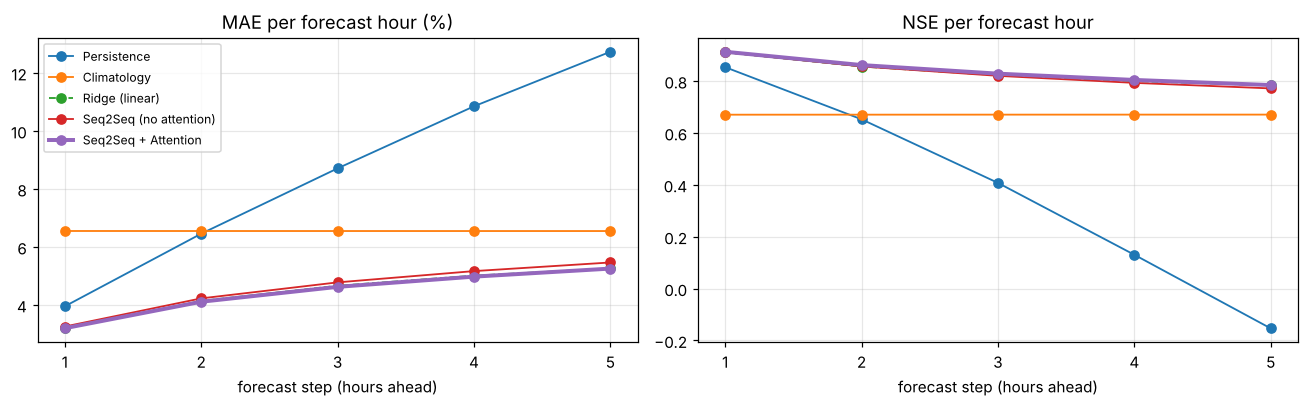

In [10]:
per = pd.DataFrame({k: {s: R[k]["per_step"][s] for s in range(1, 6)} for k in order})
tabs = {met: pd.DataFrame({k: [R[k]["per_step"][s][met] for s in range(1, 6)] for k in order}, index=[f"t+{s}" for s in range(1, 6)]).round(3) for met in ("R2", "NSE", "MAE", "RMSE")}
display(pd.concat({m: t[["Ridge (linear)", "Seq2Seq (no attention)", "Seq2Seq + Attention"]] for m, t in tabs.items()}, axis=1))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k in order:
    for a, met in zip(ax, ("MAE", "NSE")):
        a.plot(range(1, 6), [R[k]["per_step"][s][met] for s in range(1, 6)], marker="o", label=k, lw=2.6 if k == best else 1.2, ls="--" if k.startswith("Ridge") else "-")
ax[0].set_title("MAE per forecast hour (%)"); ax[1].set_title("NSE per forecast hour")
for a in ax: a.set_xlabel("forecast step (hours ahead)"); a.set_xticks(range(1, 6))
ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG / "02_per_step.png"); plt.show()

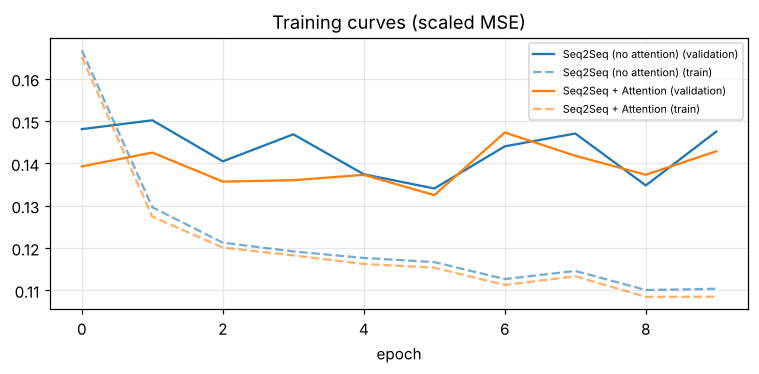

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for name, tag in (("Seq2Seq (no attention)", "noattn"), ("Seq2Seq + Attention", "attn")):
    hst = np.array(json.load(open(ROOT / "models" / f"{F}_{tag}_history.json")))
    l, = ax.plot(hst[:, 1], label=f"{name} (validation)"); ax.plot(hst[:, 0], ls="--", alpha=.6, color=l.get_color(), label=f"{name} (train)")
ax.set_title("Training curves (scaled MSE)"); ax.set_xlabel("epoch"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "03_training_curves.png"); plt.show()

## 6. Analysis of the final model — Seq2Seq + Attention

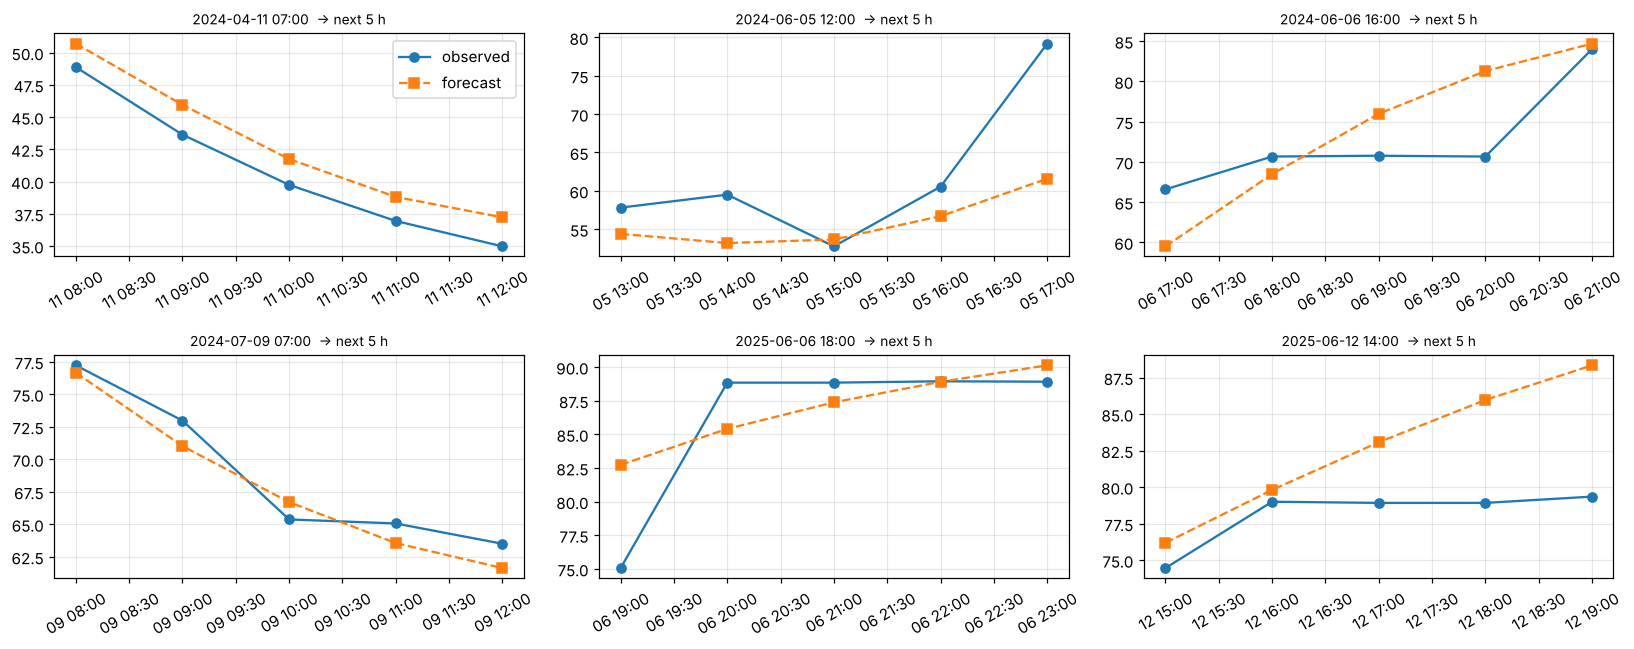

In [12]:
Pa = P[best]
rng = np.random.default_rng(3); idx = np.sort(rng.choice(len(Y), 6, replace=False))
fig, ax = plt.subplots(2, 3, figsize=(15, 6))
for a, i in zip(ax.ravel(), idx):
    t = dates[i] - pd.Timedelta(hours=4) + pd.to_timedelta(range(5), unit="h")
    a.plot(t, Y[i], "o-", label="observed"); a.plot(t, Pa[i], "s--", label="forecast")
    a.set_title(str(dates[i] - pd.Timedelta(hours=5))[:16] + "  → next 5 h", fontsize=9); a.tick_params(axis="x", labelrotation=30)
ax[0, 0].legend(); plt.tight_layout(); plt.savefig(FIG / "04_example_forecasts.png"); plt.show()

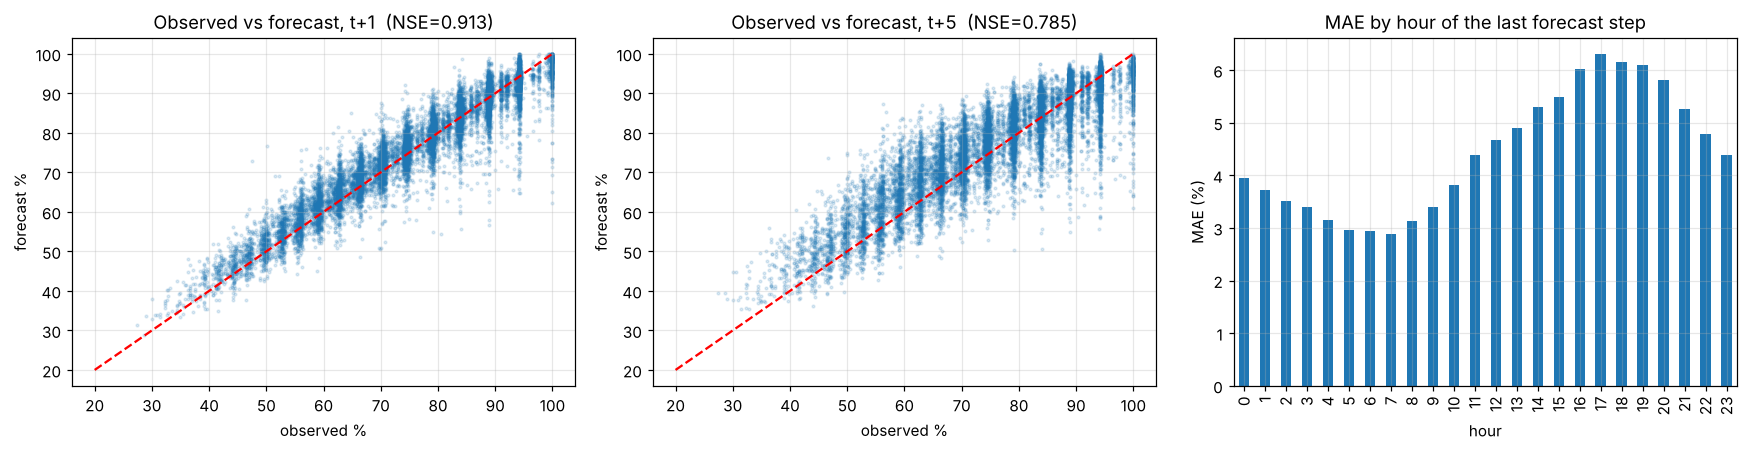

Bias (forecast - observed): overall +0.95 | most humid 5 % of observations -5.25 | driest 5 % +4.14
MAE per step  attention: [3.2, 4.11, 4.62, 4.98, 5.25] | Ridge: [3.19, 4.14, 4.66, 5.01, 5.26]


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, s in zip(ax[:2], (0, 4)):
    a.scatter(Y[:, s], Pa[:, s], s=3, alpha=.15); a.plot([20, 100], [20, 100], "r--")
    a.set_title(f"Observed vs forecast, t+{s+1}  (NSE={R[best]['per_step'][s+1]['NSE']:.3f})"); a.set_xlabel("observed %"); a.set_ylabel("forecast %")
err = pd.DataFrame({"hour": dates.hour, "abs_err": np.abs(Y - Pa).mean(1)})
err.groupby("hour").abs_err.mean().plot(ax=ax[2], kind="bar"); ax[2].set_title("MAE by hour of the last forecast step"); ax[2].set_ylabel("MAE (%)")
plt.tight_layout(); plt.savefig(FIG / "05_errors.png"); plt.show()
yy, pp = Y.ravel(), Pa.ravel(); e = pp - yy
print(f"Bias (forecast - observed): overall {e.mean():+.2f} | most humid 5 % of observations {e[yy >= np.quantile(yy, .95)].mean():+.2f} | driest 5 % {e[yy <= np.quantile(yy, .05)].mean():+.2f}")
print("MAE per step  attention:", [round(float(np.abs(Y[:, s] - Pa[:, s]).mean()), 2) for s in range(5)],
      "| Ridge:", [round(float(np.abs(Y[:, s] - P["Ridge (linear)"][:, s]).mean()), 2) for s in range(5)])

**Attention weights.** The heat-map shows, for each forecast hour (rows), how much weight the decoder puts on each of the 48 input hours (columns), averaged over test windows.

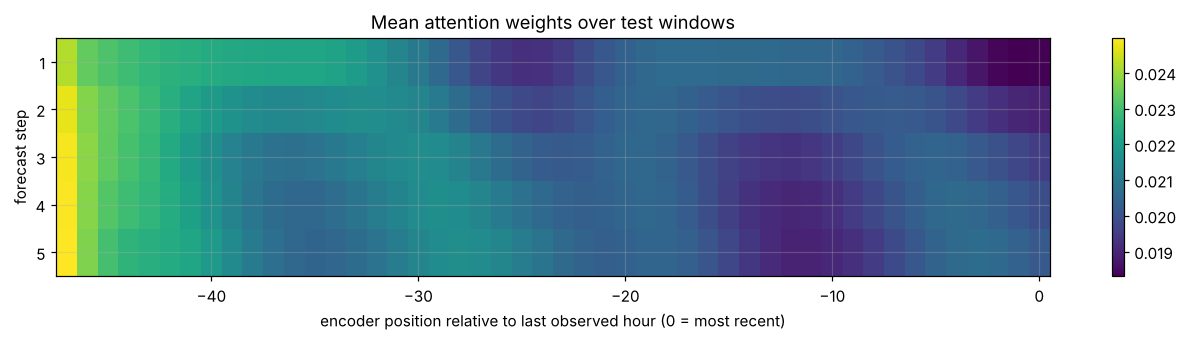

Uniform weight = 0.0208 | mean weight on newest hour = 0.0194, on oldest hour = 0.0247
Attention entropy per forecast step = [3.809999942779541, 3.799999952316284, 3.799999952316284, 3.799999952316284, 3.799999952316284]  vs  3.87 for perfectly uniform attention
Largest single weight in a window (average) = 0.043  vs  0.021 if uniform


In [14]:
A = np.load(ROOT / "reports" / "hourly_attention.npy")     # (windows, decoder steps, encoder positions)
Lb = A.shape[2]; mean_att = A.mean(0)
fig, ax = plt.subplots(figsize=(12, 3.2))
im = ax.imshow(mean_att, aspect="auto", cmap="viridis", extent=[-Lb + .5, .5, 5.5, .5])
ax.set_xlabel("encoder position relative to last observed hour (0 = most recent)"); ax.set_ylabel("forecast step")
ax.set_title("Mean attention weights over test windows"); plt.colorbar(im); plt.tight_layout(); plt.savefig(FIG / "06_attention.png"); plt.show()
ent = -(A * np.log(A + 1e-12)).sum(2).mean(0)
print(f"Uniform weight = {1/Lb:.4f} | mean weight on newest hour = {mean_att[:, -1].mean():.4f}, on oldest hour = {mean_att[:, 0].mean():.4f}")
print(f"Attention entropy per forecast step = {ent.round(2).tolist()}  vs  {np.log(Lb):.2f} for perfectly uniform attention")
print(f"Largest single weight in a window (average) = {A.max(2).mean():.3f}  vs  {1/Lb:.3f} if uniform")

## 7. Conclusions & next steps
* **Result.** The Encoder–Decoder GRU with Attention forecasts the next 5 hours of humidity with **R² = 0.842, NSE = 0.838, MAE = 4.43 %, RMSE = 6.01 %** on the held-out last 15 % of the data (Feb 2024 – Oct 2025). It clearly beats persistence (MAE 8.54) and the calendar-only climatology (MAE 6.55).
* **Honest margin over a linear model.** Ridge regression is essentially tied (MAE 4.45, RMSE 6.08): most of the predictable signal is the diurnal cycle plus the recent state, which a linear model already captures. The sequence model's edge is small.
* **Attention helps a little but is diffuse.** It improves on the no-attention seq2seq (NSE 0.838 vs 0.830, MAE 4.43 vs 4.58), yet the learned weights are close to uniform, so the decoder mostly averages the whole 48-hour window instead of locking onto particular hours.
* **Error grows with the horizon** (MAE ≈ 3.2 % at t+1 to ≈ 5.3 % at t+5), the expected behaviour for multi-step forecasting.
* **Forecasts shrink towards the mean:** the most humid 5 % of hours are under-predicted by about 5 points and the driest 5 % over-predicted by about 4.
* **Limitations:** single training seed (differences of a few hundredths between close models are within noise), no hyper-parameter search beyond the config, observed weather only (no numerical weather prediction inputs).
* **Next steps:** several seeds with confidence intervals, walk-forward cross-validation, longer look-back, LSTM / bidirectional encoder, and quantile outputs to better cover extremes.

*Reproduce:* `python -m pytest tests` → `python -m src.train hourly` → run this notebook (`RETRAIN = True` to retrain inside it).